In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

# Set dataset root
BASE_DIR = Path("dataset")

# Function to parse YOLO labels
def parse_yolo_file(file_path):
    data = []
    with open(file_path, "r") as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) == 5:
                cls, x, y, w, h = map(float, parts)
                data.append((int(cls), x, y, w, h))
    return data

In [9]:
# List a few label files
for split in ['test', 'train', 'val']:
    path = BASE_DIR / split / 'labels'
    if path.exists():
        print(f"\n{split.upper()} LABELS FOUND in: {path}")
        print("Sample files:", [f.name for f in path.glob("*.txt")][:5])
    else:
        print(f"{split.upper()} folder not found at {path}")


TEST LABELS FOUND in: dataset\test\labels
Sample files: ['box-1051-_jpg.rf.d20122197cc94f5c1359dfd2797eb4cd.txt', 'box-1054-_jpg.rf.3e2cf72436f3958fbb9e675cbc7f5bca.txt', 'box-1085-_jpg.rf.6bc0cbda75c59d7c9fedca7df142df7e.txt', 'box-1096-_jpg.rf.85f174fdc0fd7e846b7985e0b2844dee.txt', 'box-1101-_jpg.rf.986e55baf10ceceffdd6b6bb7eed7d85.txt']

TRAIN LABELS FOUND in: dataset\train\labels
Sample files: ['box-1000-_jpg.rf.5561425bbde61223013ef272742cd506.txt', 'box-1000-_jpg.rf.d2b59ac9811c6d74ad2664018974076c.txt', 'box-1000-_jpg.rf.f72bb59aee98b95bdaccd1adb326548b.txt', 'box-1001-_jpg.rf.3a4bd03c00ee279826d1efb16e3eccdd.txt', 'box-1001-_jpg.rf.b634810a2fcaf37fc7f83ee2d03014cf.txt']
VAL folder not found at dataset\val\labels


In [10]:
# Scan through all label files in train/val/test
records = []
for split in ["train", "val", "test"]:
    label_path = BASE_DIR / split / "labels"
    if not label_path.exists():
        continue
    for file in label_path.glob("*.txt"):
        data = parse_yolo_file(file)
        for cls, x, y, w, h in data:
            records.append({
                "split": split,
                "file": file.name,
                "class": cls,
                "x_center": x,
                "y_center": y,
                "width": w,
                "height": h
            })

# Convert to DataFrame
df = pd.DataFrame(records)

# Sanity check
print(f"Total labels: {len(df)}")
print(df.head())

Total labels: 2227
   split                                               file  class  x_center  \
0  train  box-1000-_jpg.rf.5561425bbde61223013ef272742cd...      0  0.574219   
1  train  box-1000-_jpg.rf.d2b59ac9811c6d74ad26640189740...      0  0.428906   
2  train  box-1000-_jpg.rf.f72bb59aee98b95bdaccd1adb3265...      0  0.571875   
3  train  box-1001-_jpg.rf.3a4bd03c00ee279826d1efb16e3ec...      0  0.580469   
4  train  box-1001-_jpg.rf.b634810a2fcaf37fc7f83ee2d0301...      0  0.571875   

   y_center     width    height  
0  0.483594  0.354687  0.506250  
1  0.526563  0.387500  0.526563  
2  0.476562  0.371875  0.517188  
3  0.510938  0.464062  0.567187  
4  0.462500  0.390625  0.523438  


Text(0, 0.5, 'Height')

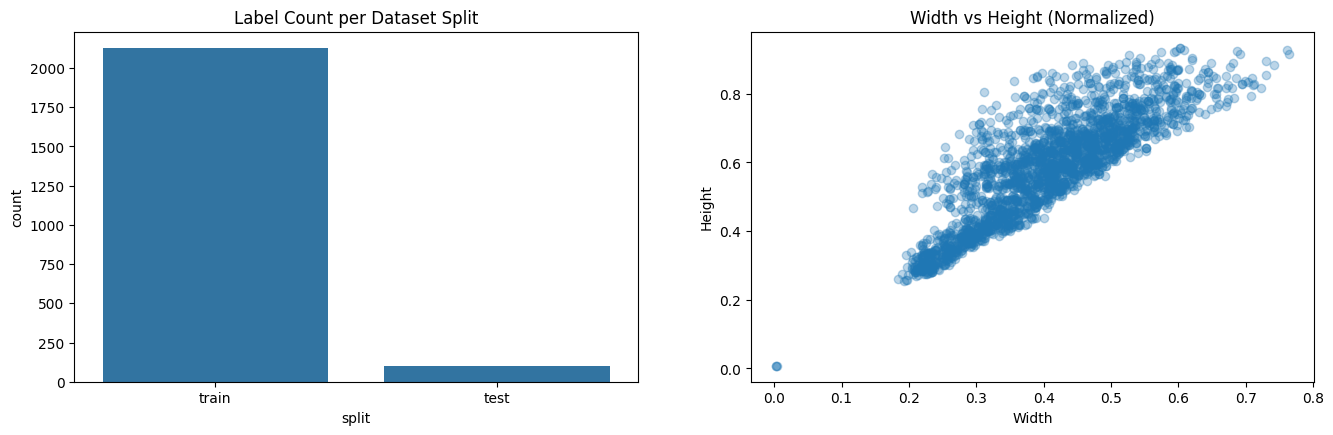

In [11]:
# Plot setup
plt.figure(figsize=(16, 10))

# 1. Label count per split
plt.subplot(2, 2, 1)
sns.countplot(data=df, x="split")
plt.title("Label Count per Dataset Split")

# 2. Width vs Height scatter
plt.subplot(2, 2, 2)
plt.scatter(df["width"], df["height"], alpha=0.3)
plt.title("Width vs Height (Normalized)")
plt.xlabel("Width")
plt.ylabel("Height")

Text(0.5, 1.0, 'Center Point Heatmap')

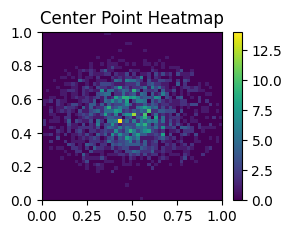

In [12]:
# 3. Heatmap of center points
plt.subplot(2, 2, 3)
heatmap_data, xedges, yedges = np.histogram2d(df["x_center"], df["y_center"], bins=50)
plt.imshow(heatmap_data.T, origin='lower', cmap='viridis', extent=[0, 1, 0, 1], aspect='auto')
plt.colorbar()
plt.title("Center Point Heatmap")

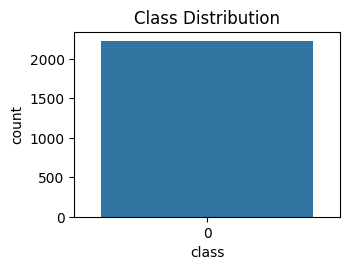

In [13]:
# 4. Class distribution
plt.subplot(2, 2, 4)
sns.countplot(data=df, x="class")
plt.title("Class Distribution")

plt.tight_layout()
plt.show()

Correlation Matrix:
               area  perimeter
area       1.00000    0.98264
perimeter  0.98264    1.00000


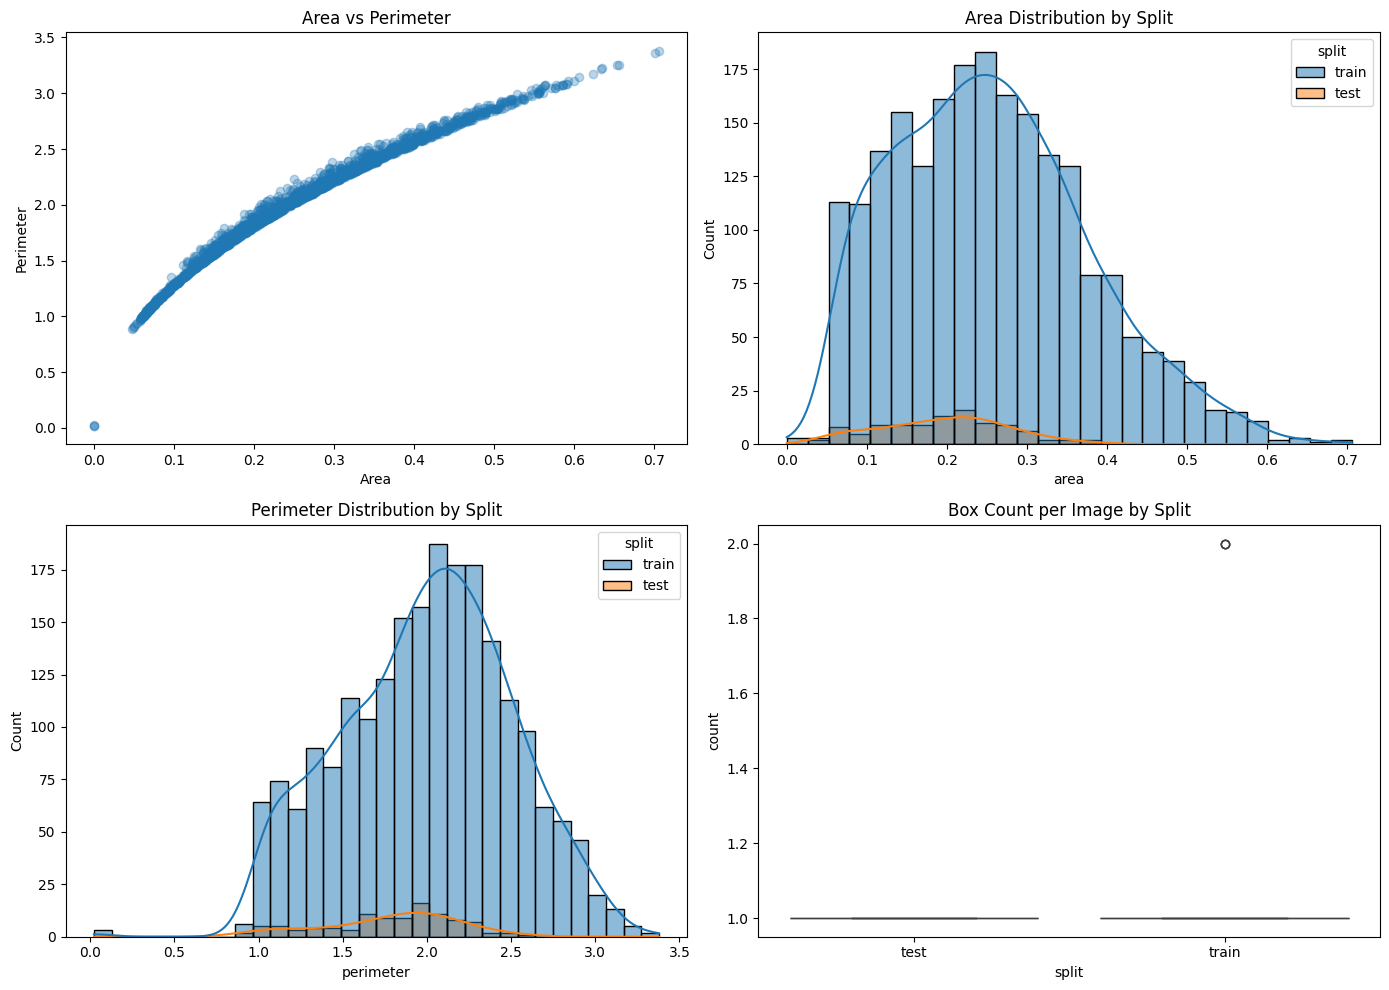

In [14]:
# Area and perimeter calculation
df['area'] = df['width'] * df['height']
df['perimeter'] = 2 * (df['width'] + df['height'])

# Correlation matrix
correlation = df[['area', 'perimeter']].corr()
print("Correlation Matrix:\n", correlation)

# Plot visualizations
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Area vs Perimeter scatter
axes[0, 0].scatter(df['area'], df['perimeter'], alpha=0.3)
axes[0, 0].set_title('Area vs Perimeter')
axes[0, 0].set_xlabel('Area')
axes[0, 0].set_ylabel('Perimeter')

# Area distribution by split
sns.histplot(data=df, x='area', hue='split', kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Area Distribution by Split')

# Perimeter distribution by split
sns.histplot(data=df, x='perimeter', hue='split', kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Perimeter Distribution by Split')

# Box count per image
box_count = df.groupby(['split', 'file']).size().reset_index(name='count')
sns.boxplot(data=box_count, x='split', y='count', ax=axes[1, 1])
axes[1, 1].set_title('Box Count per Image by Split')

plt.tight_layout()
plt.show()
